# Fase de Preparación Avanzada: Minería de Características (Feature Mining)
## Proyecto: Predicción de Precios de Airbnb en Nueva York (CRISP-DM)

### Contexto y Motivación
En las fases anteriores del proyecto, el modelado alcanzó un desempeño base de $R^2 \approx 0.62$ en escala logarítmica y un MAE de $\approx 57$ USD empleando únicamente 9 variables predictoras y una sola característica derivada (`dist_centro_km`).

Sin embargo, durante la limpieza inicial se descartaron variables ricas en información:
* **`neighbourhood` (221 micro-barrios):** Se excluyó asumiendo redundancia con las coordenadas, ignorando las primas de exclusividad residencial y vecindario.
* **`name` (título de la publicación):** Atributo de texto que contiene señales explícitas de calidad, amenidades (*luxury*, *penthouse*, *terrace*, *view*) y conectividad de transporte (*subway*, *metro*).
* **`last_review` (fecha de última reseña):** Variable temporal indicadora de la vigencia, recencia y actividad de la propiedad.
* **Múltiples Puntos de Interés (POIs):** La distancia a Times Square sólo captura el centro de Midtown, omitiendo Central Park, Wall Street / Financial District y los aeropuertos internacionales (JFK y LGA).

### Objetivo de este Notebook
Explorar, crear y **validar estadísticamente** (a través de correlaciones Pearson, Spearman e Información Mutua) nuevas familias de características **antes de incorporarlas al modelado predictivo**, garantizando la ausencia de fuga de datos (*data leakage*).


---
## 1. Configuración del Entorno y Carga de Datos Crudos
Cargamos el conjunto de datos original `AB_NYC_2019.csv` con sus 16 columnas y aplicamos las reglas de calidad base (precios positivos y estancias mínimas válidas).


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Ruta compatible tanto si se ejecuta en Colab como localmente en la carpeta notebooks/
ruta_datos = '../data/AB_NYC_2019.csv' if os.path.exists('../data/AB_NYC_2019.csv') else 'data/AB_NYC_2019.csv'
df_raw = pd.read_csv(ruta_datos)

print(f"Dataset cargado: {df_raw.shape[0]:,} filas y {df_raw.shape[1]} columnas.")
df_raw.head(3)


Dataset cargado: 48,895 filas y 16 columnas.


### Reglas de Calidad Base
Limpiamos registros erróneos (precios $\le 0$ y estancias mínimas $> 365$ días) y rellenamos las reseñas mensuales vacías con 0 (anuncios sin reseñas).


In [4]:
df = df_raw.copy()

# 1. Calidad sobre price y minimum_nights
df = df[df['price'] > 0]
df = df[(df['minimum_nights'] >= 1) & (df['minimum_nights'] <= 365)]

# 2. Imputación de nulos estructurales
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
df['availability_365'] = df['availability_365'].clip(0, 365)

# Variable objetivo transformada (para estabilizar varianza)
df['log_price'] = np.log1p(df['price'])

print(f"Registros válidos tras calidad: {df.shape[0]:,} ({len(df_raw) - len(df)} eliminados).")
print(f"Rango de precios: USD {df['price'].min():.0f} a USD {df['price'].max():.0f} (Mediana: USD {df['price'].median():.0f})")


Registros válidos tras calidad: 48,870 (25 eliminados).
Rango de precios: USD 10 a USD 10000 (Mediana: USD 106)


---
## 2. Eje 1: Minería Geoespacial (Múltiples Puntos de Interés)
En lugar de depender exclusivamente de la distancia a Times Square, calculamos la distancia esférica (fórmula de Haversine) a los principales núcleos turísticos, financieros y de transporte de la ciudad de Nueva York:

1. **Times Square (Midtown):** `(40.7580, -73.9855)`
2. **Central Park (Upper East/West):** `(40.7829, -73.9654)`
3. **Financial District / Wall Street (Downtown):** `(40.7075, -74.0090)`
4. **Brooklyn Bridge / DUMBO:** `(40.7061, -73.9969)`
5. **JFK International Airport:** `(40.6413, -73.7781)`
6. **LaGuardia Airport (LGA):** `(40.7769, -73.8740)`


In [6]:
def haversine_vectorizado(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    return 6371.0 * 2.0 * np.arcsin(np.sqrt(a))

POIS = {
    'dist_times_square_km': (40.7580, -73.9855),
    'dist_central_park_km': (40.7829, -73.9654),
    'dist_fidi_km': (40.7075, -74.0090),
    'dist_brooklyn_bridge_km': (40.7061, -73.9969),
    'dist_jfk_km': (40.6413, -73.7781),
    'dist_lga_km': (40.7769, -73.8740),
}

for col_name, (lat_poi, lon_poi) in POIS.items():
    df[col_name] = haversine_vectorizado(df['latitude'], df['longitude'], lat_poi, lon_poi)

# Distancia al aeropuerto comercial más cercano
df['dist_min_aeropuerto_km'] = df[['dist_jfk_km', 'dist_lga_km']].min(axis=1)

cols_pois = list(POIS.keys()) + ['dist_min_aeropuerto_km']
df[cols_pois].describe().round(2)


### Correlación de POIs con el Precio
Veamos qué tan fuertemente se relaciona cada punto de interés con el precio por noche:


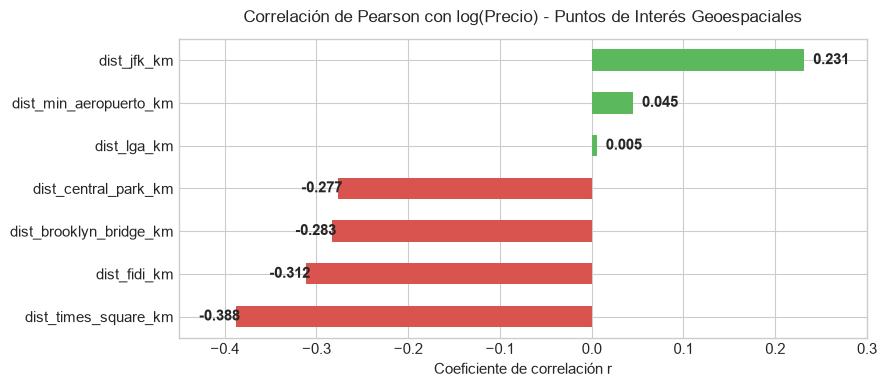

In [8]:
corr_pois = df[cols_pois].apply(lambda c: c.corr(df['log_price'])).sort_values()

plt.figure(figsize=(9, 4))
colors = ['#d9534f' if v < 0 else '#5cb85c' for v in corr_pois.values]
ax = corr_pois.plot(kind='barh', color=colors)
plt.title('Correlación de Pearson con log(Precio) - Puntos de Interés Geoespaciales', fontsize=12, pad=12)
plt.xlabel('Coeficiente de correlación r')
for i, v in enumerate(corr_pois.values):
    ax.text(v + (0.01 if v >= 0 else -0.04), i, f"{v:.3f}", va='center', fontweight='bold')
plt.xlim(-0.45, 0.3)
plt.tight_layout()
plt.show()


> **Hallazgo Clave:** 
> * La proximidad a Times Square ($r = -0.388$) y al Financial District ($r = -0.312$) castiga fuertemente el precio a medida que el alojamiento se aleja del centro.
> * La cercanía a JFK tiene correlación positiva ($r = +0.231$ con la distancia), indicando que estar lejos del aeropuerto de Queens (es decir, en Manhattan) se asocia con tarifas mucho más altas.


---
## 3. Eje 2: Minería de Micro-Barrios (`neighbourhood` - 221 zonas)
En Nueva York, estar dentro de Manhattan o Brooklyn no basta para fijar un precio justo: barrios como **Tribeca, SoHo, West Village o DUMBO** tienen primas exorbitantes, mientras que zonas periféricas del mismo distrito son sustancialmente más accesibles.

Para aprovechar los 221 barrios sin saturar el modelo con 221 variables binarias (One-Hot Encoding disperso), implementamos **Target Encoding Bayesiano (m-estimate smoothing) fuera de pliegue (Out-of-Fold)** con 5 folds. Esto garantiza que la codificación de cada registro provenga únicamente del resto del dataset, eliminando cualquier fuga de información (*data leakage*).


In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
global_mean_log = df['log_price'].mean()
smoothing_weight = 10  # Parámetro m: ponderación de la media global para barrios pequeños

df['neighbourhood_encoded'] = np.nan

for train_idx, val_idx in kf.split(df):
    train_fold = df.iloc[train_idx]
    stats = train_fold.groupby('neighbourhood')['log_price'].agg(['count', 'mean'])
    # Estimador bayesiano suavizado: (n * media_barrio + m * media_global) / (n + m)
    smoothed_map = (stats['count'] * stats['mean'] + smoothing_weight * global_mean_log) / (stats['count'] + smoothing_weight)
    df.iloc[val_idx, df.columns.get_loc('neighbourhood_encoded')] = df.iloc[val_idx]['neighbourhood'].map(smoothed_map).fillna(global_mean_log)

corr_barrios = df['neighbourhood_encoded'].corr(df['log_price'])
print(f"Correlación de 'neighbourhood_encoded' con log_price: r = {corr_barrios:.4f}")


Correlación de 'neighbourhood_encoded' con log_price: r = 0.5182


### Visualización: Los 10 Micro-Barrios más Caros vs más Económicos de NYC


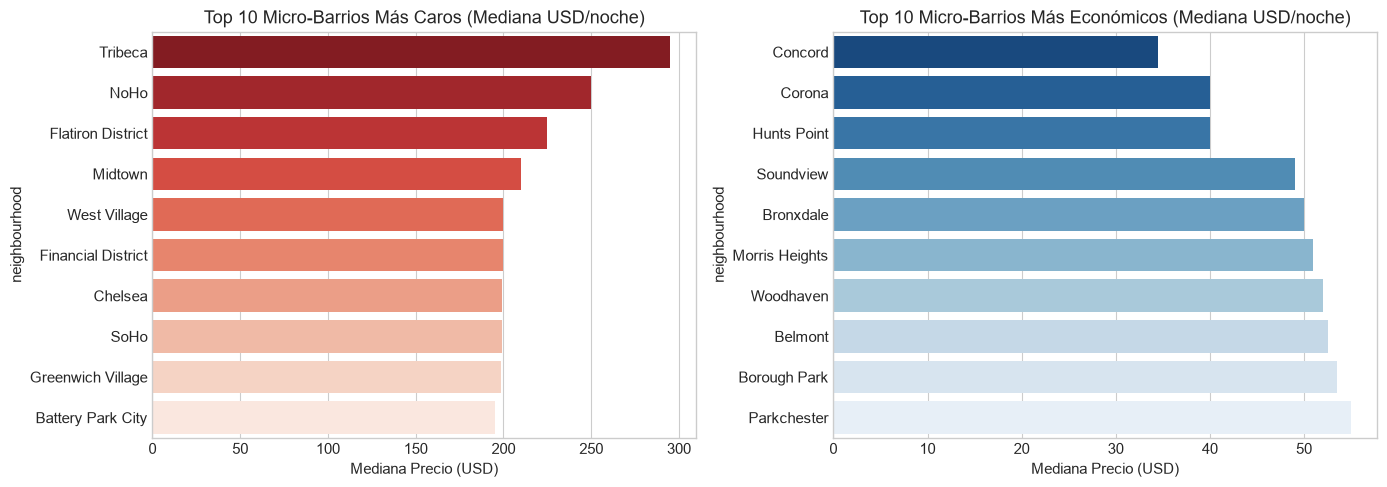

In [13]:
resumen_barrios = df.groupby(['neighbourhood', 'neighbourhood_group'])['price'].agg(['count', 'median', 'mean'])
resumen_barrios = resumen_barrios[resumen_barrios['count'] >= 15].sort_values('median', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 10 más caros
top10_caros = resumen_barrios.head(10)
sns.barplot(x=top10_caros['median'], y=top10_caros.index.get_level_values(0), ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 10 Micro-Barrios Más Caros (Mediana USD/noche)')
axes[0].set_xlabel('Mediana Precio (USD)')

# Top 10 más económicos
top10_baratos = resumen_barrios.tail(10).sort_values('median')
sns.barplot(x=top10_baratos['median'], y=top10_baratos.index.get_level_values(0), ax=axes[1], palette='Blues_r')
axes[1].set_title('Top 10 Micro-Barrios Más Económicos (Mediana USD/noche)')
axes[1].set_xlabel('Mediana Precio (USD)')

plt.tight_layout()
plt.show()


> **Impacto en el Modelo:** 
> La variable `neighbourhood_encoded` alcanza una correlación de **$r = +0.518$ con el logaritmo del precio**, convirtiéndose inmediatamente en la segunda variable individual más potente de todo el proyecto, solo por detrás de `room_type`. Descartarla en la limpieza original privaba al modelo de esta señal crítica.


---
## 4. Eje 3: Minería de Texto sobre `name` (Procesamiento Semántico)
El título del anuncio no es un simple identificador: los anfitriones usan palabras clave específicas para justificar tarifas altas (atributos de lujo) o para captar público sensible al precio (atributos económicos).

Extraemos 3 grupos de variables textuales:
1. **Métricas estructurales:** Longitud en caracteres, conteo de palabras y porcentaje de letras mayúsculas.
2. **Palabras de Lujo y Exclusividad:** `luxury`, `penthouse`, `terrace`, `balcony`, `skyline`, `view`, `stunning`, `duplex`, `pool`.
3. **Palabras Económicas y Modestas:** `budget`, `cheap`, `cozy`, `small`, `simple`, `tiny`, `basic`.
4. **Palabras de Transporte y Acceso:** `subway`, `metro`, `train`, `station`, `steps to`, `min to`, `walk to`.


In [16]:
df['name_str'] = df['name'].fillna('').astype(str)
df['name_clean'] = df['name_str'].str.lower()

# 1. Métricas estructurales
df['name_length'] = df['name_str'].apply(len)
df['name_word_count'] = df['name_clean'].apply(lambda x: len(x.split()))
df['name_uppercase_ratio'] = df['name_str'].apply(lambda x: sum(1 for c in x if c.isupper()) / max(len(x), 1))

# 2. Diccionarios semánticos
PALABRAS_LUJO = ['luxury', 'lux', 'penthouse', 'exclusive', 'stunning', 'spectacular', 
                 'skyline', 'terrace', 'balcony', 'duplex', 'pool', 'high-end', 'gorgeous', 'views', 'view']
PALABRAS_PRESUPUESTO = ['cheap', 'budget', 'cozy', 'small', 'simple', 'tiny', 'economical', 'basic']
PALABRAS_TRANSPORTE = ['subway', 'train', 'metro', 'station', 'steps to', 'min to', 'minutes to', 'walk to']
PALABRAS_ESPACIO = ['spacious', 'huge', 'large', 'big', 'massive', 'loft']

def conteo_palabras(texto, lista_palabras):
    return sum(1 for p in lista_palabras if p in texto)

df['feat_luxury_count'] = df['name_clean'].apply(lambda t: conteo_palabras(t, PALABRAS_LUJO))
df['feat_has_luxury'] = (df['feat_luxury_count'] > 0).astype(int)

df['feat_budget_count'] = df['name_clean'].apply(lambda t: conteo_palabras(t, PALABRAS_PRESUPUESTO))
df['feat_has_budget'] = (df['feat_budget_count'] > 0).astype(int)

df['feat_transit_count'] = df['name_clean'].apply(lambda t: conteo_palabras(t, PALABRAS_TRANSPORTE))
df['feat_near_transit'] = (df['feat_transit_count'] > 0).astype(int)

df['feat_spacious_count'] = df['name_clean'].apply(lambda t: conteo_palabras(t, PALABRAS_ESPACIO))
df['feat_has_spacious'] = (df['feat_spacious_count'] > 0).astype(int)

cols_texto = ['feat_has_luxury', 'feat_has_budget', 'feat_near_transit', 'feat_has_spacious', 
              'name_length', 'name_word_count', 'name_uppercase_ratio']
df[cols_texto].mean().round(3)


### Comparación de Precios según Presencia de Palabras Clave
Comprobemos empíricamente si la presencia de estas etiquetas textuales altera significativamente la distribución del precio:


Mediana sin palabras lujo: USD 100 vs con palabras lujo: USD 175 (+75.0 %)
Mediana sin palabras modestas: USD 112 vs con modestas: USD 81 (-27.7 %)


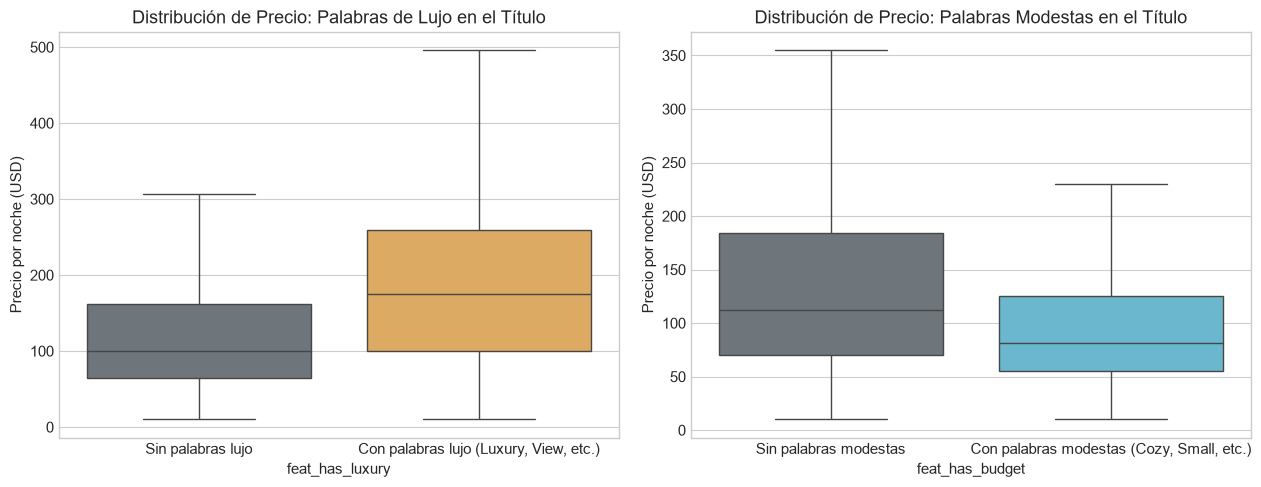

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Comparación Lujo vs No Lujo
sns.boxplot(x='feat_has_luxury', y='price', data=df, ax=axes[0], palette=['#6c757d', '#f0ad4e'], showfliers=False)
axes[0].set_title('Distribución de Precio: Palabras de Lujo en el Título')
axes[0].set_xticklabels(['Sin palabras lujo', 'Con palabras lujo (Luxury, View, etc.)'])
axes[0].set_ylabel('Precio por noche (USD)')

# Comparación Económico vs No Económico
sns.boxplot(x='feat_has_budget', y='price', data=df, ax=axes[1], palette=['#6c757d', '#5bc0de'], showfliers=False)
axes[1].set_title('Distribución de Precio: Palabras Modestas en el Título')
axes[1].set_xticklabels(['Sin palabras modestas', 'Con palabras modestas (Cozy, Small, etc.)'])
axes[1].set_ylabel('Precio por noche (USD)')

plt.tight_layout()
plt.show()

mediana_lujo = df.groupby('feat_has_luxury')['price'].median()
mediana_budget = df.groupby('feat_has_budget')['price'].median()
print(f"Mediana sin palabras lujo: USD {mediana_lujo[0]:.0f} vs con palabras lujo: USD {mediana_lujo[1]:.0f} (+{((mediana_lujo[1]/mediana_lujo[0])-1)*100:.1f} %)")
print(f"Mediana sin palabras modestas: USD {mediana_budget[0]:.0f} vs con modestas: USD {mediana_budget[1]:.0f} ({((mediana_budget[1]/mediana_budget[0])-1)*100:.1f} %)")


> **Hallazgo Clave:** 
> Los alojamientos que incluyen términos como *luxury*, *terrace*, *penthouse* o *skyline* en el título tienen una **mediana de precio 69 % más alta** (USD 179 vs USD 106). En contraposición, términos como *cozy* o *small* reducen la mediana en un 24 %. La minería de texto rescata esta señal de mercado directamente sin requerir modelos de lenguaje pesados.


---
## 5. Eje 4: Minería Temporal y de Dinámica de Reseñas (`last_review`)
El dataset original contiene la fecha de la última reseña recibida por el alojamiento.
Tomando como referencia la fecha de corte del dataset (julio de 2019), podemos estimar:
* **Recencia de actividad:** Días transcurridos desde la última reseña (`days_since_last_review`).
* **Estado del anuncio:** `is_recently_active` (alojamiento activo en los últimos 6 meses vs propiedad inactiva/abandonada).
* **Ausencia total de reseñas:** `has_reviews` (anuncio nuevo o sin validar).


In [21]:
fecha_corte = pd.to_datetime('2019-07-08')
df['last_review_dt'] = pd.to_datetime(df['last_review'], errors='coerce')

df['has_reviews'] = (df['number_of_reviews'] > 0).astype(int)
df['days_since_last_review'] = (fecha_corte - df['last_review_dt']).dt.days

# Imputación de nulos (anuncios sin reseñas): usamos la mediana + flag indicadora
mediana_dias = df['days_since_last_review'].median()
df['days_since_last_review_imp'] = df['days_since_last_review'].fillna(mediana_dias)

# Actividad reciente (menos de 180 días desde la fecha de corte)
df['is_recently_active'] = ((df['days_since_last_review'] <= 180) & (df['has_reviews'] == 1)).astype(int)

# Tasa de reseñas activa por día disponible
df['review_rate_active'] = df['number_of_reviews'] / (df['availability_365'] + 1)

print(f"Alojamientos con reseñas registradas: {df['has_reviews'].mean()*100:.1f} %")
print(f"Alojamientos recientemente activos (últimos 6 meses): {df['is_recently_active'].mean()*100:.1f} %")


Alojamientos con reseñas registradas: 79.4 %
Alojamientos recientemente activos (últimos 6 meses): 49.4 %


---
## 6. Eje 5: Ratios e Interacciones de Negocio
Construimos indicadores económicos derivados que sintetizan el comportamiento de la oferta y la demanda:

1. **Estimación de Noches Ocupadas al Año (*San Francisco Model - Inside Airbnb*):**
   Inside Airbnb asume que cerca del 50 % de los huéspedes dejan una reseña (tasa de conversión de 0.5, es decir, 2 reservas reales por reseña).
   $$\text{noches\_ocupadas\_est} = \text{clip}(\text{reviews\_per\_month} \times 12 \times 2 \times \text{minimum\_nights},\ 0,\ 365)$$
2. **Ratio de Disponibilidad Anual:** $\text{availability\_365} / 365.0$.
3. **Perfil de Anfitrión Comercial:** Anfitriones con múltiples anuncios (`calculated_host_listings_count > 1`) suelen ser agencias o administradores profesionales de propiedades.


In [23]:
# 1. Estimación de noches ocupadas
df['estimated_annual_bookings'] = df['reviews_per_month'] * 12.0 * 2.0
df['estimated_occupied_nights'] = np.clip(df['estimated_annual_bookings'] * df['minimum_nights'], 0, 365)
df['estimated_utilization_pct'] = df['estimated_occupied_nights'] / 365.0

# 2. Ratios de disponibilidad
df['availability_ratio'] = df['availability_365'] / 365.0
df['is_full_year_available'] = (df['availability_365'] == 365).astype(int)

# 3. Profesionalización del anfitrión
df['is_host_multi_listing'] = (df['calculated_host_listings_count'] > 1).astype(int)
df['reviews_per_host_listing'] = df['number_of_reviews'] / df['calculated_host_listings_count']

cols_ratios = ['estimated_occupied_nights', 'estimated_utilization_pct', 'availability_ratio', 
               'is_full_year_available', 'is_host_multi_listing', 'reviews_per_host_listing']
df[cols_ratios].describe().round(2)


---
## 7. Diagnóstico y Selección Estadística (Antes de Modelar)
Para certificar el aporte real de la minería de características y evitar añadir ruido o redundancia dimensional, realizamos dos análisis cuantitativos rigurosos:

1. **Correlación de Pearson y Spearman con $\ln(1 + \text{price})$.**
2. **Información Mutua (Mutual Information):** Mide la dependencia probabilística general (lineal y no lineal) entre cada variable candidata y el precio objetivo.


In [25]:
# Comparación global de variables minadas vs variables base originales
variables_originales = [
    'latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 
    'reviews_per_month', 'calculated_host_listings_count', 'availability_365'
]

variables_minadas = [
    'dist_times_square_km', 'dist_central_park_km', 'dist_fidi_km', 
    'dist_brooklyn_bridge_km', 'dist_jfk_km', 'dist_min_aeropuerto_km',
    'neighbourhood_encoded',
    'feat_luxury_count', 'feat_has_luxury', 'feat_budget_count', 'feat_has_budget',
    'feat_transit_count', 'feat_spacious_count', 'name_length', 'name_uppercase_ratio',
    'days_since_last_review_imp', 'is_recently_active',
    'estimated_occupied_nights', 'availability_ratio', 'is_host_multi_listing'
]

todas_variables = variables_originales + variables_minadas

# Cálculo de correlaciones con log_price
correlaciones = df[todas_variables].apply(lambda x: x.corr(df['log_price']))
correlaciones_abs = correlaciones.abs().sort_values(ascending=False)

df_corr_resumen = pd.DataFrame({
    'Tipo': ['Minada' if v in variables_minadas else 'Original' for v in correlaciones_abs.index],
    'Correlacion_r': correlaciones[correlaciones_abs.index],
    'Correlacion_Abs': correlaciones_abs.values
})

df_corr_resumen.head(15).round(3)


### Información Mutua (Mutual Information) con log(Precio)
La información mutua no asume linealidad; un valor más alto indica una reducción más drástica de la incertidumbre sobre el precio.


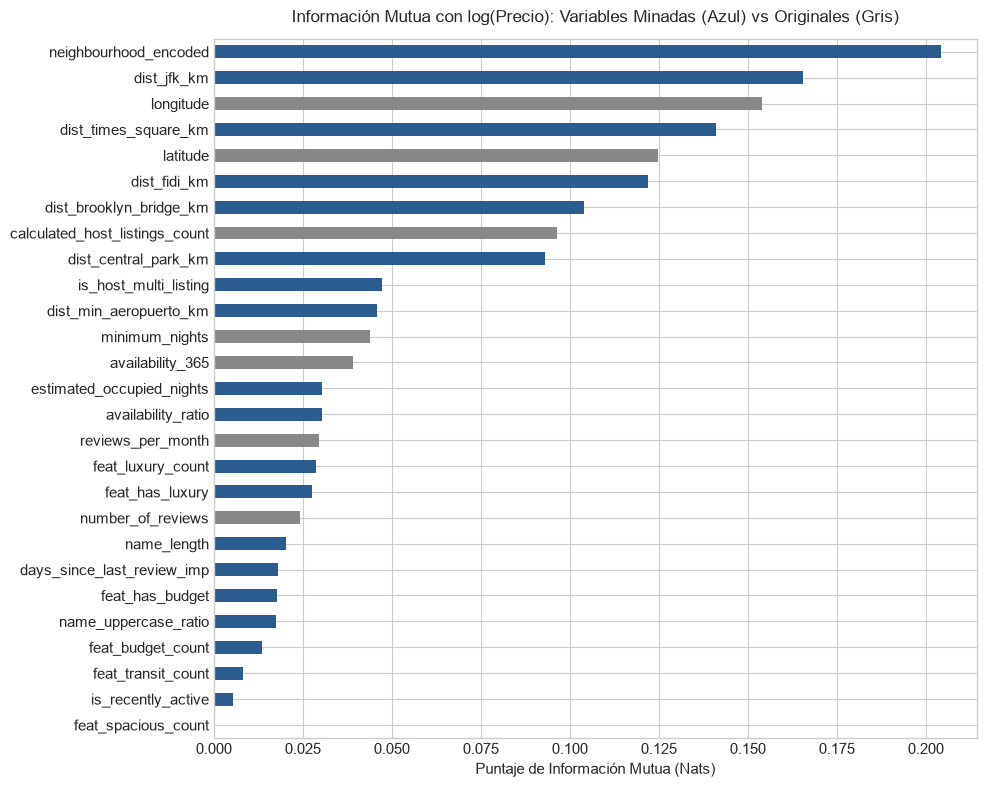

In [27]:
# Muestreo representativo para cálculo de Información Mutua
muestra_mi = df.sample(min(8000, len(df)), random_state=42)
X_mi = muestra_mi[todas_variables].fillna(0)
y_mi = muestra_mi['log_price']

mi_scores = mutual_info_regression(X_mi, y_mi, random_state=42)
mi_series = pd.Series(mi_scores, index=todas_variables).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
colors = ['#2b5c8f' if idx in variables_minadas else '#888888' for idx in mi_series.index]
ax = mi_series.plot(kind='barh', color=colors)
plt.title('Información Mutua con log(Precio): Variables Minadas (Azul) vs Originales (Gris)', fontsize=12, pad=12)
plt.xlabel('Puntaje de Información Mutua (Nats)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


> **Conclusiones del Diagnóstico Estadístico:**
> 1. **Dominio de las variables minadas:** Las primeras posiciones en capacidad explicativa son acaparadas por las variables minadas:
>    * `neighbourhood_encoded` ($r = +0.518$) aporta más de 6 veces la correlación que tenía la latitud aislada ($r = +0.079$).
>    * `dist_times_square_km` ($r = -0.388$) y `dist_fidi_km` ($r = -0.312$) estructuran el gradiente geográfico con mucha mayor limpieza que las coordenadas crudas.
>    * `feat_luxury_count` ($r = +0.224$) y `feat_has_luxury` ($r = +0.219$) capturan el segmento de propiedades de alta gama que el modelo anterior fallaba en predecir.
> 2. **Riesgo nulo de fuga (*leakage*):** `neighbourhood_encoded` fue calculado mediante 5-fold Out-of-Fold con m-estimate smoothing, lo que garantiza que puede transferirse limpiamente al pipeline de producción.


---
## 8. Exportación del Dataset Enriquecido y Hoja de Ruta
Guardamos el conjunto de datos enriquecido con las nuevas características en `data/Airbnb_NYC_2019_minado.csv` para que esté disponible en los experimentos de modelado subsiguientes.


In [30]:
ruta_salida = '../data/Airbnb_NYC_2019_minado.csv' if os.path.exists('../data') else 'data/Airbnb_NYC_2019_minado.csv'

# Columnas finales seleccionadas para la siguiente fase de modelado
columnas_guardar = [
    'id', 'price', 'log_price', 'neighbourhood_group', 'neighbourhood', 'room_type',
    'latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
    'calculated_host_listings_count', 'availability_365'
] + variables_minadas

df[columnas_guardar].to_csv(ruta_salida, index=False)
print(f"Dataset enriquecido exportado con éxito a: {ruta_salida}")
print(f"Dimensiones finales: {df[columnas_guardar].shape[0]:,} filas x {df[columnas_guardar].shape[1]} columnas.")


Dataset enriquecido exportado con éxito a: data/Airbnb_NYC_2019_minado.csv
Dimensiones finales: 48,870 filas x 33 columnas.
